# Unit Search That Scales on Asteroids RAM

> **Overview.** 03's unit search, changed by general rules until more LTUs, with nothing else changed, predict the next
> Asteroids RAM state better. Set `WIDTHS` to the numbers of LTUs to compare.

**Setup.** The data and scores of `02_world_model.ipynb`: transitions from mode 0, difficulty 0, learned once in time
order; inputs the 1,024 RAM bits and a one-hot action, standardized online; one logit per next-RAM bit, trained with
cross-entropy. The learner is 03's (network Autostep, the outputs reading every input as a linear learner, LTUs with
shadow weights, fast learning of new LTUs, input growth, search every 10k steps replacing up to 1/8 of the LTUs) with
one hidden layer and these changes:

1. **Step-size caps**: 0.1 on every weight, 1e-3 on the outputs' weights on LTUs (without them Autostep blows up on
   rarely-firing bits and LTUs, see 03's diagnosis).
2. **Sparse LTU→output connections**: a new LTU feeds only its parent output; an output starts reading another LTU by
   the same gradient-sum rule that grows the LTUs' inputs. Dense connections made more LTUs add noise to every output.
3. **Parents in proportion to loss**: each new LTU's parent output is drawn in proportion to that output's loss over the
   last search period (uniformly at the start), so outputs that are already predicted well get no LTUs.
4. **Usefulness as the loss an LTU's removal would add**: to second order, the sum over the outputs it feeds of its
   weight² times the mean of p (1 − p), p the output's predicted probability, over the last search period. It replaces
   the sum of |outgoing weights|, which counts weights on outputs that are already certain.
5. **Protection while rising**: an LTU can be replaced only if its usefulness has not risen since the last search step,
   instead of after a fixed age.

400k steps, 3 seeds per width; the linear learner alone (no LTUs) as the baseline.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

## Data and settings

In [2]:
# --- Data (as in 02_world_model.ipynb) ---
DATA_FILE = 'data_mode0_diff0.npz'
N_STEPS = 400_000                    # transitions learned from, in order
LOG_EVERY = N_STEPS // 100           # steps per plotted average
N_ACTIONS = 14
N_INPUTS, N_OUTPUTS = 1024 + N_ACTIONS, 1024    # RAM bits and the one-hot action in, next-RAM bits out

# --- Learner ---
WIDTHS = [150, 600]                  # numbers of LTUs compared, one run of N_SEEDS seeds each
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the inputs and hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
STEP_CAP, LTU_STEP_CAP = 0.1, 1e-3   # largest step-size of any weight, and of the outputs' weights on LTUs
FAN_IN = 30                          # a new LTU first reads this many sources
REPLACED_SHARE = 1 / 8               # largest share of the LTUs replaced at each search step, the weakest
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # a unit connects a source whose gradient sum is this many RMS above the rest
WINDOW = 1_000                       # steps between growth steps
PERIOD = 10_000                      # steps between search steps
N_SEEDS = 3

data = np.load(DATA_FILE)
valid = data['valid']
ram, action, next_ram = (data['ram'][:-1][valid][:N_STEPS], data['action'][valid][:N_STEPS],
                         data['ram'][1:][valid][:N_STEPS])
DATA = tuple(jnp.asarray(v) for v in (ram, action, next_ram))

# Bytes counted in the accuracy, as in Veličković et al. 2021: those whose next value has entropy above 0.6 nats.
p = np.stack([np.bincount(byte, minlength=256) for byte in next_ram.T]) / len(next_ram)
VARIED = -(p * np.log(np.where(p > 0, p, 1))).sum(1) > 0.6
RMR_ACCURACY = 0.8069  # Veličković et al. 2021, Table 2, Asteroids, message-passing network

# Reference: copy the current RAM. For the loss, each bit keeps its value with probability 1 - q, where q is the
# fraction of bits that change. Both over the last 10% of steps.
last = slice(-N_STEPS // 10, None)
q = (np.unpackbits(ram[last], axis=1) != np.unpackbits(next_ram[last], axis=1)).mean()
copy_final = [-(q * np.log(q) + (1 - q) * np.log(1 - q)), (ram[last][:, VARIED] == next_ram[last][:, VARIED]).mean()]

## Learner

In [3]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped like the LTUs.
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


def set_width(width):
    # Sizes the learner: N_LTUS LTUs, of which search replaces at most REPLACED; READABLE, which sources of [inputs,
    # LTUs, 1] an LTU may read: the inputs and the bias (the LTUs' columns keep 03's layout, one source vector for all).
    global N_LTUS, REPLACED, READABLE
    N_LTUS = width
    REPLACED = round(REPLACED_SHARE * N_LTUS)
    READABLE = jnp.ones(N_INPUTS + N_LTUS + 1, bool).at[N_INPUTS:-1].set(False)


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, LTUs, 1 (the bias)], of which they read those in `reads`;
    # w['output'] is the outputs' weights over [inputs (the linear learner), LTUs, 1], of which they read those in `mask`.
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + N_LTUS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each LTU's shadow weight, +-1 on its parent output, 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS + N_LTUS): sum of dL/dz * source since each LTU's last new input
    out_candidates: jax.Array   # (N_OUTPUTS, N_LTUS): sum of dL/dlogit * LTU since each output's last new LTU
    input_mean: jax.Array       # (N_INPUTS,): running mean of each input bit
    loss_sum: jax.Array         # (N_OUTPUTS,): sum, this search period, of each output's loss
    curv_sum: jax.Array         # (N_OUTPUTS,): sum, this search period, of p (1 - p), the loss's curvature in the logit
    prev_use: jax.Array         # (N_LTUS,): each LTU's usefulness at the last search step (0 when it was wired)


def active(net):
    # Which slots hold an LTU.
    return jnp.any(net.shadow != 0, 0)


def parent_weights(net):
    # Shaped like w['hidden']: each LTU's shadow weight times its parent output's weights on the inputs (the linear
    # learner's), 0 elsewhere and on the bias.
    return (net.shadow.T @ net.w['output']).at[:, -1].set(0.0) * READABLE


def usefulness(net):
    # The loss each LTU's removal would add, to second order: the sum over the outputs reading it of its weight squared
    # times the output's mean p (1 - p) over this search period.
    return (net.w['output'][:, N_INPUTS:-1] ** 2 * net.mask[:, N_INPUTS:-1] * net.curv_sum[:, None]).sum(0) / PERIOD


def init_net(units):
    # `units` LTUs (the rest of the N_LTUS slots left empty), with shadow weights +1 and -1 alternately on the first
    # output (redrawn, and the LTUs wired, when they are added); every weight 0, the outputs reading every input and the
    # bias (the linear learner) and no LTU, and the inputs' running means at 0.5.
    slot = jnp.arange(N_LTUS)
    sign = jnp.where(slot < units, jnp.where(slot % 2 == 0, 1.0, -1.0), 0.0)
    shadow = jnp.zeros((N_OUTPUTS, N_LTUS)).at[0].set(sign)
    mask = jnp.ones((N_OUTPUTS, N_INPUTS + N_LTUS + 1), bool).at[:, N_INPUTS:-1].set(False)
    w = {'hidden': jnp.zeros((N_LTUS, N_INPUTS + N_LTUS + 1)), 'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, jnp.zeros(w['hidden'].shape, bool), mask, OPTIMIZER.init(w), stats, shadow,
               jnp.zeros((N_LTUS, N_INPUTS + N_LTUS)), jnp.zeros((N_OUTPUTS, N_LTUS)), jnp.full(N_INPUTS, 0.5),
               jnp.zeros(N_OUTPUTS), jnp.zeros(N_OUTPUTS), jnp.zeros(N_LTUS))


def redraw(net, key, replaced):
    # The `replaced` LTUs' new shadow weights, +1 or -1 by slot, each on a parent output drawn with probability
    # proportional to the outputs' losses over this search period (uniformly before any loss is measured).
    _, unit_key = jax.random.split(key)
    total = net.loss_sum.sum()
    index = jax.random.categorical(unit_key, jnp.where(total > 0, jnp.log(net.loss_sum / total), 0.0), shape=(N_LTUS,))
    sign = jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == index) * sign
    return net._replace(shadow=jnp.where(replaced, shadow, net.shadow))


def rewire(net, key, rows, random):
    # The `rows` LTUs each read FAN_IN inputs (no more than their parent has nonzero weights on) and the bias, drawn
    # without replacement with probability proportional to the square of their parent's weight on them (uniformly, if
    # random) (Gumbel top-k), with fresh LeCun uniform weights over their fan-in; feed only their parent output, at
    # weight 0; and get fresh statistics, Autostep state and gradient sums.
    draw_key, w_key = jax.random.split(key)
    weights = jnp.where(random, READABLE[None], parent_weights(net))[:, :-1]
    fan_in = jnp.minimum(FAN_IN, (weights != 0).sum(1, keepdims=True))
    scores = jnp.log(weights ** 2) + jax.random.gumbel(draw_key, weights.shape)
    reads = jnp.append(jnp.argsort(jnp.argsort(-scores)) < fan_in, jnp.ones((N_LTUS, 1), bool), axis=1)
    hidden = (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / jnp.maximum(fan_in, 1))
              * reads)
    where = {'hidden': rows[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), rows, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    w = reset(net.w, {'hidden': hidden.at[:, -1].set(0.0), 'output': jnp.zeros_like(net.w['output'])})
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    beta = reset(net.opt.beta, jax.tree.map(lambda a: a + net.opt.init_beta, zeros))
    opt = net.opt._replace(beta=beta, h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(rows, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    mask = net.mask.at[:, N_INPUTS:-1].set(jnp.where(rows[None], net.shadow != 0, net.mask[:, N_INPUTS:-1]))
    return net._replace(w=w, reads=jnp.where(rows[:, None], reads, net.reads), mask=mask, opt=opt, stats=stats,
                        candidates=jnp.where(rows[:, None], 0.0, net.candidates),
                        out_candidates=jnp.where(rows[None], 0.0, net.out_candidates))


def speed_up(net, rows):
    # The `rows` LTUs' weights keep their magnitudes but take the signs of their shadow weight times their parent's
    # weights on those inputs (keeping theirs where that weight is 0), and the step-sizes of all their weights but the
    # bias's start at FAST_STEP_SIZE.
    sources = net.reads.at[:, -1].set(False) & rows[:, None]
    parent = parent_weights(net)
    hidden = jnp.where(sources & (parent != 0), jnp.abs(net.w['hidden']) * jnp.sign(parent), net.w['hidden'])
    beta = jnp.where(sources, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': hidden}, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = READABLE[None, :-1] & ~net.reads[:, :-1]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = (jnp.max(sums, 1) > GROW_Z * rms) & active(net)
    new = (jnp.arange(N_INPUTS + N_LTUS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def grow_outputs(net):
    # Each output whose largest gradient sum, over the LTUs it does not read, is more than GROW_Z times their root mean
    # square starts reading that LTU, at weight 0 with Autostep's initial step-size, and restarts its sums.
    unread = ~net.mask[:, N_INPUTS:-1] & active(net)[None]
    sums = jnp.where(unread, jnp.abs(net.out_candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / jnp.maximum(unread.sum(1), 1))
    grows = (jnp.max(sums, 1) > GROW_Z * rms) & unread.any(1)
    new = (jnp.arange(N_LTUS) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    cols = jnp.zeros_like(net.mask).at[:, N_INPUTS:-1].set(new)
    zero = lambda t: {**t, 'output': jnp.where(cols, 0.0, t['output'])}
    beta = {**net.opt.beta, 'output': jnp.where(cols, net.opt.init_beta, net.opt.beta['output'])}
    return net._replace(w=zero(net.w), mask=net.mask | cols,
                        opt=net.opt._replace(beta=beta, h=zero(net.opt.h), v=zero(net.opt.v)),
                        out_candidates=jnp.where(grows[:, None], 0.0, net.out_candidates))


def learn(net, ram, action, next_ram):
    # One online network-Autostep update on the cross-entropy summed over the outputs, each the logit of a next-RAM bit,
    # with step-sizes capped at STEP_CAP (LTU_STEP_CAP on the outputs' weights on LTUs). The inputs are the RAM's bits
    # and the one-hot action, standardized with running means like the LTUs; each shadow weight stands in for its LTU's
    # weight to its parent in the backward pass while the real one is smaller in magnitude. Returns the new network and,
    # on this sample before learning from it, the cross-entropy of each bit and the fraction of varying bytes exactly
    # right; adds dL/dz * input to each LTU's gradient sums, dL/dlogit * LTU to each output's, and each output's loss and
    # p (1 - p) to its sums. `probe` is zero; its gradients are the error arriving at each LTU and dL/dz.
    bits = jnp.concatenate([jnp.unpackbits(ram).astype(jnp.float32), jax.nn.one_hot(action, N_ACTIONS)])
    input_mean = net.input_mean + STAT_RATE * (bits - net.input_mean)
    x = (bits - input_mean) / jnp.sqrt(jnp.maximum(input_mean * (1 - input_mean), VAR_FLOOR))
    y = jnp.unpackbits(next_ram).astype(jnp.float32)

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}
        z = w['hidden'] @ jax.lax.stop_gradient(jnp.concatenate([x, jnp.zeros(N_LTUS), jnp.ones(1)]))
        b = ltu(z + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = h + probe[0]
        source = jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)]))
        real = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(real) < 1.0), net.shadow, real))
        through_back = (back * net.mask[:, N_INPUTS:-1]) @ a
        logits = w['output'] @ source + through_back - jax.lax.stop_gradient(through_back)
        return optax.sigmoid_binary_cross_entropy(logits, y).sum(), (source, jax.lax.stop_gradient(h), mean, logits)

    (_, (source, h, mean, logits)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    sources = {'hidden': source[None] * net.reads, 'output': source[None] * net.mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    beta = jax.tree.map(lambda b: jnp.minimum(b, np.log(STEP_CAP)), opt.beta)
    opt = opt._replace(beta={**beta, 'output': beta['output'].at[:, N_INPUTS:-1].min(np.log(LTU_STEP_CAP))})
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    loss = optax.sigmoid_binary_cross_entropy(logits, y)
    accuracy = ((logits > 0) == (y > 0.5)).reshape(-1, 8).all(1).mean(where=VARIED)
    unread = (jax.nn.sigmoid(logits) - y)[:, None] * source[None, N_INPUTS:-1]
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * source[:-1], input_mean=input_mean,
                        out_candidates=net.out_candidates + jnp.where(net.mask[:, N_INPUTS:-1], 0.0, unread),
                        loss_sum=net.loss_sum + loss,
                        curv_sum=net.curv_sum + jax.nn.sigmoid(logits) * jax.nn.sigmoid(-logits)), \
        jnp.append(loss, accuracy)

## Training

In [4]:
def train(net, key, data):
    # N_STEPS online steps on the transitions in data (ram, action, next_ram), in order. The LTUs are wired at step 0
    # (their inputs drawn uniformly, since their parents have no weights yet); every WINDOW steps each LTU and output
    # grows; every PERIOD steps the up to REPLACED least useful LTUs whose usefulness has not risen since the last search
    # step get new parents and are rewired, and the search period's sums restart. Returns the cross-entropy of each bit
    # and the fraction of varying bytes exactly right, averaged over every LOG_EVERY steps, shaped
    # (N_STEPS // LOG_EVERY, N_OUTPUTS + 1).

    def start(net, key, replaced, random):
        # The replaced LTUs given new parents, rewired and sped up.
        redraw_key, wire_key = jax.random.split(key)
        net = redraw(net, redraw_key, replaced)
        return speed_up(rewire(net, wire_key, replaced, random), replaced)

    def window(net, index):
        net, scores = jax.lax.scan(lambda net, step: learn(net, *(v[step] for v in data)), net,
                                   index * WINDOW + jnp.arange(WINDOW))
        net = grow_outputs(grow(net))
        outgoing = usefulness(net)
        eligible = jnp.where(active(net) & (outgoing <= net.prev_use), outgoing, jnp.inf)
        weakest = jnp.argsort(eligible)[:REPLACED]
        replaced = jnp.zeros(N_LTUS, bool).at[weakest].set(jnp.isfinite(eligible[weakest]))
        searched = start(net, jax.random.fold_in(key, index), replaced, False)
        searched = searched._replace(loss_sum=jnp.zeros_like(net.loss_sum), curv_sum=jnp.zeros_like(net.curv_sum),
                                     prev_use=jnp.where(replaced, 0.0, outgoing))
        due = (index + 1) * WINDOW % PERIOD == 0
        return jax.tree.map(lambda a, b: jnp.where(due, a, b), searched, net), scores.mean(0)

    net = start(net, key, active(net), True)
    scores = jax.lax.scan(window, net, jnp.arange(N_STEPS // WINDOW))[1]
    return scores.reshape(-1, LOG_EVERY // WINDOW, N_OUTPUTS + 1).mean(1)


def run(units):
    # Each number of LTUs in `units` (0: the linear learner alone) on N_SEEDS seeds, vmapped together at the current
    # width. Seeds differ only in the random draws of parents and wiring. Returns {units: the cross-entropy of each bit
    # and the fraction of varying bytes exactly right, shaped (seed, point, N_OUTPUTS + 1)}.
    count, seed = (jnp.array(v) for v in zip(*[(u, s) for u in units for s in range(N_SEEDS)]))
    keys = jax.random.split(jax.random.PRNGKey(1), N_SEEDS)[seed]
    scores = jax.jit(jax.vmap(train, in_axes=(0, 0, None)))(jax.vmap(init_net)(count), keys, DATA)
    return dict(zip(units, np.asarray(scores).reshape(len(units), N_SEEDS, -1, N_OUTPUTS + 1)))

## Run

In [5]:
# Each width in its own run; the linear learner alone runs with the first.
scores, LINEAR = {}, 0
for i, width in enumerate(WIDTHS):
    set_width(width)
    started = perf_counter()
    scores.update(run([width, LINEAR] if i == 0 else [width]))
    print(f'{width} LTUs: {N_SEEDS} seeds in {perf_counter() - started:.0f}s')
last = slice(-scores[LINEAR].shape[1] // 10, None)
for units, s in scores.items():
    print(f'{units:5d} LTUs, last 10%: cross-entropy per bit {s[:, last, :-1].mean():.4f}, '
          f'varying bytes right {s[:, last, -1].mean():.3f}')

150 LTUs: 3 seeds in 367s


600 LTUs: 3 seeds in 312s
  150 LTUs, last 10%: cross-entropy per bit 0.1166, varying bytes right 0.783
    0 LTUs, last 10%: cross-entropy per bit 0.1265, varying bytes right 0.751
  600 LTUs, last 10%: cross-entropy per bit 0.1041, varying bytes right 0.815


Text(0.5, 0.98, 'Learning Curve | Asteroids Next-RAM Prediction, Unit Search at 2 Widths (3 seeds)')

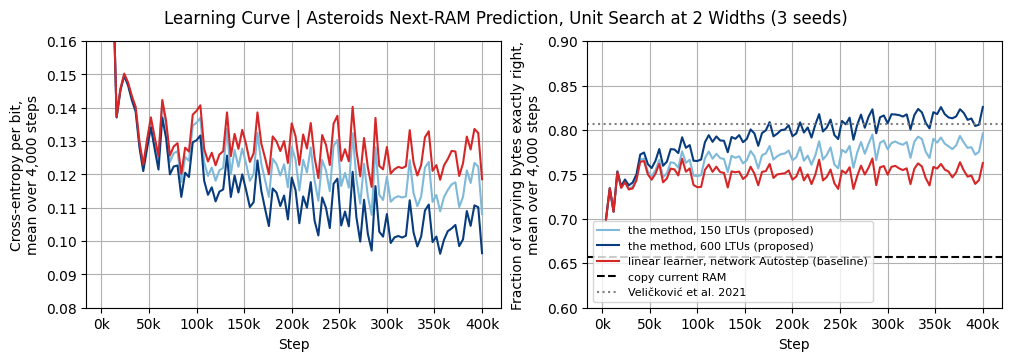

In [6]:
steps = LOG_EVERY * np.arange(1, N_STEPS // LOG_EVERY + 1)   # end of each average
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
names = ['Cross-entropy per bit', 'Fraction of varying bytes exactly right']
colors = plt.cm.Blues(np.linspace(0.45, 0.95, len(WIDTHS)))
curves = {f'the method, {w} LTUs (proposed)': (w, c) for w, c in zip(WIDTHS, colors)}
curves['linear learner, network Autostep (baseline)'] = (LINEAR, 'tab:red')
for label, (units, color) in curves.items():
    s = scores[units].mean(0)
    for ax, values in zip(axes, (s[:, :-1].mean(1), s[:, -1])):
        ax.plot(steps, values, color=color, label=label)
for ax, ref, name in zip(axes, copy_final, names):
    ax.axhline(ref, color='k', ls='--', label='copy current RAM')
    ax.set(xlabel='Step', ylabel=f'{name},\nmean over {LOG_EVERY:,} steps')
    ax.xaxis.set_major_formatter(lambda v, _: f'{v / 1000:.0f}k')
    ax.grid()
axes[0].set_ylim(0.08, 0.16)
axes[1].set_ylim(0.6, 0.9)
axes[1].axhline(RMR_ACCURACY, color='gray', ls=':', label='Veličković et al. 2021')
axes[1].legend(fontsize=8)
fig.suptitle(f'Learning Curve | Asteroids Next-RAM Prediction, Unit Search at {len(WIDTHS)} Widths ({N_SEEDS} seeds)')